# Assignment 4 - Search in Complex Environments

Used codex to generate a cleaner jupyter notebook to work out of 

In [1]:
import heapq
import os

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({
    'figure.dpi': 100,
    'figure.figsize': (7, 4.2),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11,
})


---
## 1. Annealing


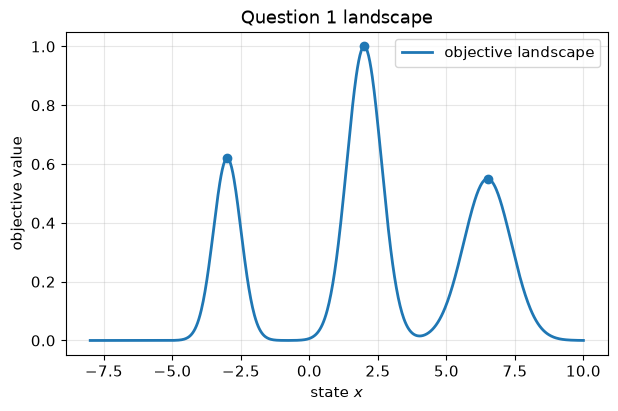

In [2]:
# The one-dimensional landscape supplied in the Module 4 notebook.
def landscape(x):
    return (1.00*np.exp(-(x-2.0)**2/0.8)   # global maximum near x = 2
            + 0.62*np.exp(-(x+3.0)**2/0.5) # local maximum near x = -3
            + 0.55*np.exp(-(x-6.5)**2/1.5))# local maximum near x = 6.5

xs = np.linspace(-8, 10, 800)
plt.plot(xs, landscape(xs), lw=2, label='objective landscape')
plt.scatter([2, -3, 6.5], [landscape(2), landscape(-3), landscape(6.5)], zorder=3)
plt.title('Question 1 landscape')
plt.xlabel('state $x$')
plt.ylabel('objective value')
plt.legend()
plt.show()

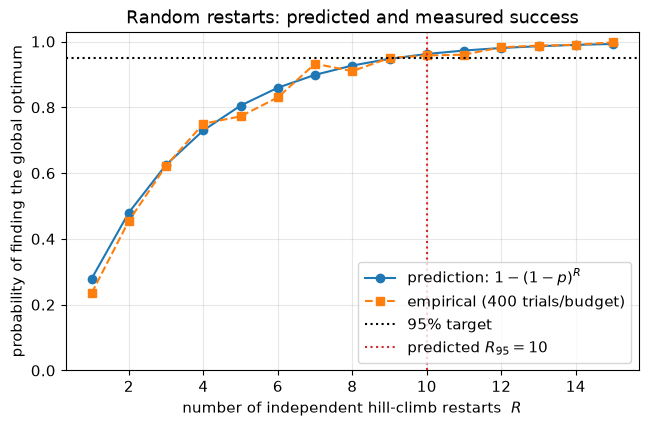

Per-run hill-climb success p = 0.279; predicted R_95 = 10 restarts.
Empirical success at R_95 = 0.958.


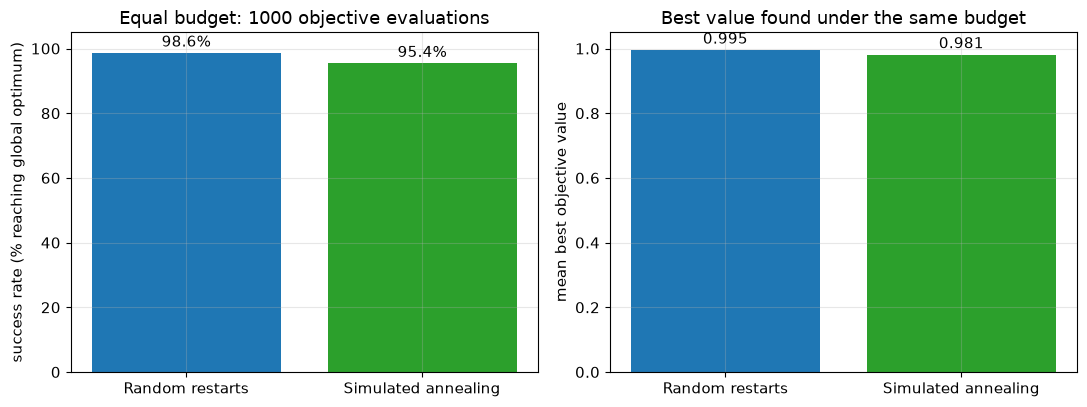

Random restarts: success=0.986, mean best value=0.995, mean evaluations used=999.5, mean restarts=14.9
Simulated annealing: success=0.954, mean best value=0.981, mean evaluations used=1000


In [3]:
# Assignment 4, Question 1: random restarts and a fair SA comparison
# Count every call to landscape() as one objective-function evaluation.
Q1_RNG = np.random.default_rng(2026)
GLOBAL_X, SUCCESS_TOL = 2.0, 0.30

def is_global(x):
    return abs(x - GLOBAL_X) < SUCCESS_TOL

def hill_climb_counted(start, eval_budget=np.inf, step=0.05, lo=-8, hi=10):
    """Steepest-ascent hill climb, returning its best point and evaluation count."""
    x = float(start)
    value = landscape(x); evaluations = 1
    best_x, best_value = x, value
    while evaluations + 2 <= eval_budget:
        candidates = [x-step, x+step]
        candidate_values = [landscape(c) for c in candidates]
        evaluations += 2
        j = int(np.argmax(candidate_values))
        if candidate_values[j] <= value:
            break
        x, value = candidates[j], candidate_values[j]
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value, evaluations

def random_restart(n_restarts, rng):
    best_x, best_value = None, -np.inf
    for _ in range(n_restarts):
        x, value, _ = hill_climb_counted(rng.uniform(-8, 10))
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value

def random_restart_budget(eval_budget, rng):
    """Use restarts until an objective-evaluation budget is exhausted."""
    used = runs = 0; best_x, best_value = None, -np.inf
    while used + 3 <= eval_budget:  # one start evaluation and at least one comparison
        x, value, cost = hill_climb_counted(rng.uniform(-8, 10), eval_budget-used)
        used += cost; runs += 1
        if value > best_value:
            best_x, best_value = x, value
    return best_x, best_value, used, runs

def simulated_annealing_counted(start, eval_budget, rng,
                                T0=2.0, alpha=0.995, prop_sd=0.7,
                                lo=-8, hi=10):
    """SA using the same accounting: one evaluation for the start and each proposal."""
    x = float(start); value = landscape(x); evaluations = 1
    best_x, best_value, T = x, value, T0
    while evaluations < eval_budget and T >= 1e-8:
        proposal = np.clip(x + rng.normal(0, prop_sd), lo, hi)
        proposal_value = landscape(proposal); evaluations += 1
        dE = proposal_value - value
        if dE > 0 or rng.random() < np.exp(dE / T):
            x, value = proposal, proposal_value
        if value > best_value:
            best_x, best_value = x, value
        T *= alpha
    return best_x, best_value, evaluations

# (a) Estimate per-run p and the restart count needed for 95% success.
N_BASELINE = 1000
baseline_starts = Q1_RNG.uniform(-8, 10, N_BASELINE)
baseline = [hill_climb_counted(s) for s in baseline_starts]
p_hat = np.mean([is_global(x) for x, _, _ in baseline])
r_95 = int(np.ceil(np.log(1 - 0.95) / np.log(1 - p_hat)))

restart_budgets = np.arange(1, 16)
N_RESTART_TRIALS = 400
empirical_success = []
for budget in restart_budgets:
    successes = [is_global(random_restart(budget, Q1_RNG)[0])
                 for _ in range(N_RESTART_TRIALS)]
    empirical_success.append(np.mean(successes))
empirical_success = np.array(empirical_success)
predicted_success = 1 - (1-p_hat)**restart_budgets

plt.figure(figsize=(7.4, 4.4))
plt.plot(restart_budgets, predicted_success, 'o-', label=r'prediction: $1-(1-p)^{R}$')
plt.plot(restart_budgets, empirical_success, 's--', label=f'empirical ({N_RESTART_TRIALS} trials/budget)')
plt.axhline(0.95, color='k', ls=':', label='95% target')
plt.axvline(r_95, color='C3', ls=':', label=f'predicted $R_{{95}}={r_95}$')
plt.xlabel('number of independent hill-climb restarts  $R$')
plt.ylabel('probability of finding the global optimum')
plt.ylim(0, 1.03); plt.legend(); plt.title('Random restarts: predicted and measured success')
plt.show()
print(f'Per-run hill-climb success p = {p_hat:.3f}; predicted R_95 = {r_95} restarts.')
print(f'Empirical success at R_95 = {empirical_success[r_95-1]:.3f}.')

# (b) Equal budget: each method receives exactly 1,000 objective evaluations per trial.
EVAL_BUDGET, N_FAIR_TRIALS = 1000, 500
restart_results, sa_results, restart_evals, restart_runs = [], [], [], []
for _ in range(N_FAIR_TRIALS):
    x_rr, value_rr, used_rr, runs_rr = random_restart_budget(EVAL_BUDGET, Q1_RNG)
    x_sa, value_sa, used_sa = simulated_annealing_counted(
        Q1_RNG.uniform(-8, 10), EVAL_BUDGET, Q1_RNG)
    restart_results.append((x_rr, value_rr))
    sa_results.append((x_sa, value_sa))
    restart_evals.append(used_rr); restart_runs.append(runs_rr)

methods = ['Random restarts', 'Simulated annealing']
success_rates = [np.mean([is_global(x) for x, _ in restart_results]),
                 np.mean([is_global(x) for x, _ in sa_results])]
mean_best_values = [np.mean([value for _, value in restart_results]),
                    np.mean([value for _, value in sa_results])]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].bar(methods, 100*np.array(success_rates), color=['C0', 'C2'])
ax[0].set_ylabel('success rate (% reaching global optimum)'); ax[0].set_ylim(0, 105)
ax[0].set_title(f'Equal budget: {EVAL_BUDGET} objective evaluations')
for i, rate in enumerate(success_rates):
    ax[0].text(i, 100*rate + 2, f'{100*rate:.1f}%', ha='center')
ax[1].bar(methods, mean_best_values, color=['C0', 'C2'])
ax[1].set_ylabel('mean best objective value'); ax[1].set_ylim(0, 1.05)
ax[1].set_title('Best value found under the same budget')
for i, value in enumerate(mean_best_values):
    ax[1].text(i, value + .02, f'{value:.3f}', ha='center')
plt.tight_layout(); plt.show()

print(f'Random restarts: success={success_rates[0]:.3f}, mean best value={mean_best_values[0]:.3f}, '
      f'mean evaluations used={np.mean(restart_evals):.1f}, mean restarts={np.mean(restart_runs):.1f}')
print(f'Simulated annealing: success={success_rates[1]:.3f}, mean best value={mean_best_values[1]:.3f}, '
      f'mean evaluations used={EVAL_BUDGET:.0f}')

---
## 2. Potential fields

*Add the U-trap layout, escape-method comparison, and written explanation here.*

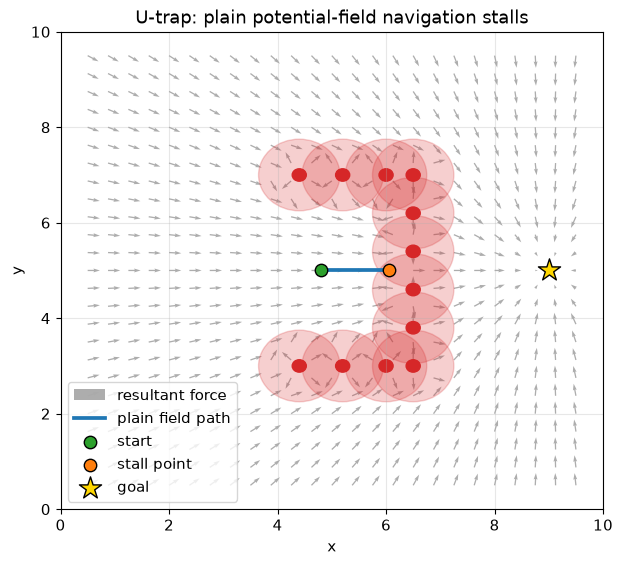

Plain field result: stalled; final position = [6.06 5.  ]; path length = 1.30.


In [4]:
# Question 2: Potential fields in a concave U-trap
GOAL_2 = np.array([9.0, 5.0])
K_ATT_2, K_REP_2, VMAX_2 = 1.0, 2.0, 1.2

# A U open to the left: the robot starts inside; the goal is behind the back wall.
U_TRAP = []
for y in np.arange(3.0, 7.01, 0.8):
    U_TRAP.append((np.array([6.5, y]), 0.75))       # back wall
for x in np.arange(4.4, 6.51, 0.8):
    U_TRAP.extend([(np.array([x, 3.0]), 0.75),      # lower arm
                   (np.array([x, 7.0]), 0.75)])     # upper arm

def potential_force(p, obstacles=U_TRAP):
    """Attractive goal force plus inverse-distance obstacle repulsion."""
    f = GOAL_2 - p
    for center, influence_radius in obstacles:
        displacement = p - center
        distance = np.linalg.norm(displacement)
        if 1e-6 < distance < influence_radius:
            f += (K_REP_2 * (1/distance - 1/influence_radius)
                  / distance**2 * displacement/distance)
    return f

def capped(vector, limit=VMAX_2):
    magnitude = np.linalg.norm(vector)
    return vector if magnitude <= limit else vector * limit/magnitude

def navigate_u_trap(start, mode='plain', rng=None, dt=0.06, max_steps=1200):
    """Run a reactive field navigator with optional structured or random recovery."""
    rng = np.random.default_rng() if rng is None else rng
    p = np.array(start, dtype=float)
    path, recovery_direction, recovery_steps = [p.copy()], None, 0
    slack_steps = 0

    for _ in range(max_steps):
        raw = potential_force(p)
        if np.linalg.norm(raw) < 0.08:
            slack_steps += 1
        else:
            slack_steps = 0

        # A recovery is injected only at a force dead-spot.  The tangential
        # primitive is a directed sideways motion around the closest obstacle;
        # the random-kick version uses the same magnitude and duration but a
        # random direction.
        if recovery_steps == 0 and slack_steps >= 1 and mode != 'plain':
            if mode == 'tangential':
                closest_center = min(U_TRAP, key=lambda item: np.linalg.norm(p-item[0]))[0]
                radial = p - closest_center
                recovery_direction = np.array([-radial[1], radial[0]])
                recovery_direction /= np.linalg.norm(recovery_direction)
            elif mode == 'random_kick':
                recovery_direction = rng.normal(size=2)
                recovery_direction /= np.linalg.norm(recovery_direction)
            recovery_steps = 18
            slack_steps = 0

        if recovery_steps:
            velocity = VMAX_2 * recovery_direction
            recovery_steps -= 1
        else:
            velocity = capped(raw)

        if mode == 'plain' and slack_steps >= 20:
            return np.array(path), False, 'stalled'
        p = np.clip(p + dt*velocity, 0.1, 9.9)
        path.append(p.copy())
        if np.linalg.norm(p - GOAL_2) < 0.25:
            return np.array(path), True, 'goal'
    return np.array(path), False, 'timeout'

def draw_u_trap(ax):
    for center, radius in U_TRAP:
        ax.add_patch(plt.Circle(center, radius, color='C3', alpha=0.22))
        ax.add_patch(plt.Circle(center, 0.13, color='C3'))

def path_length(path):
    return np.linalg.norm(np.diff(path, axis=0), axis=1).sum()

# (a) Quiver plot and plain reactive run: the resultant force vanishes at the back wall.
grid_x, grid_y = np.meshgrid(np.linspace(0.5, 9.5, 25), np.linspace(0.5, 9.5, 25))
field_u, field_v = np.zeros_like(grid_x), np.zeros_like(grid_y)
for row in range(grid_x.shape[0]):
    for col in range(grid_x.shape[1]):
        vector = capped(potential_force(np.array([grid_x[row, col], grid_y[row, col]])))
        field_u[row, col], field_v[row, col] = vector

plain_path, plain_success, plain_status = navigate_u_trap([4.8, 5.0], 'plain')
fig, ax = plt.subplots(figsize=(7, 6.2))
ax.quiver(grid_x, grid_y, field_u, field_v, color='0.60', alpha=0.8, label='resultant force')
draw_u_trap(ax)
ax.plot(plain_path[:, 0], plain_path[:, 1], color='C0', lw=2.7, label='plain field path')
ax.scatter(*plain_path[0], color='C2', edgecolor='k', s=80, zorder=5, label='start')
ax.scatter(*plain_path[-1], color='C1', edgecolor='k', s=80, zorder=5, label='stall point')
ax.scatter(*GOAL_2, color='gold', marker='*', edgecolor='k', s=280, zorder=5, label='goal')
ax.set(xlim=(0, 10), ylim=(0, 10), xlabel='x', ylabel='y',
       title='U-trap: plain potential-field navigation stalls')
ax.legend(loc='lower left'); plt.show()
print(f'Plain field result: {plain_status}; final position = {plain_path[-1].round(2)}; '
      f'path length = {path_length(plain_path):.2f}.')

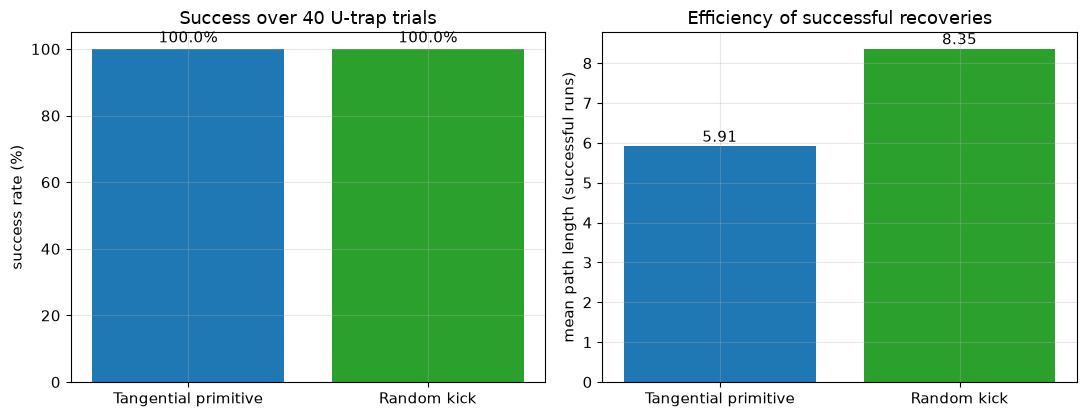

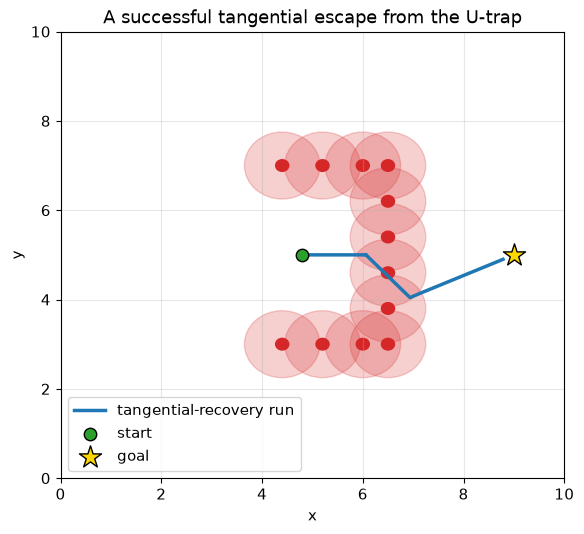

Tangential primitive: success=1.000; mean successful path length=5.909
Random kick: success=1.000; mean successful path length=8.355


In [5]:
# (b) Compare structured tangential recovery with random kicks over >= 30 runs.
N_TRIALS = 40
trial_rng = np.random.default_rng(204)
records = {'tangential': [], 'random_kick': []}

for _ in range(N_TRIALS):
    # Small start-state variation makes the evaluation stochastic but reproducible.
    start = np.array([4.8 + trial_rng.normal(0, 0.08),
                      5.0 + trial_rng.normal(0, 0.20)])
    for method in records:
        path, success, status = navigate_u_trap(start, method, trial_rng)
        records[method].append({'success': success, 'length': path_length(path),
                                'path': path, 'status': status})

methods = ['tangential', 'random_kick']
labels = ['Tangential primitive', 'Random kick']
success_rate = [np.mean([r['success'] for r in records[m]]) for m in methods]
mean_success_length = [np.mean([r['length'] for r in records[m] if r['success']])
                       for m in methods]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ax[0].bar(labels, 100*np.array(success_rate), color=['C0', 'C2'])
ax[0].set(ylim=(0, 105), ylabel='success rate (%)',
          title=f'Success over {N_TRIALS} U-trap trials')
for i, rate in enumerate(success_rate):
    ax[0].text(i, 100*rate + 2, f'{100*rate:.1f}%', ha='center')
ax[1].bar(labels, mean_success_length, color=['C0', 'C2'])
ax[1].set(ylabel='mean path length (successful runs)',
          title='Efficiency of successful recoveries')
for i, length in enumerate(mean_success_length):
    ax[1].text(i, length + .12, f'{length:.2f}', ha='center')
plt.tight_layout(); plt.show()

# Color-code one successful tangential run: blue = normal field, orange = recovery motion.
demo_path, demo_success, _ = navigate_u_trap([4.8, 5.0], 'tangential', np.random.default_rng(9))
fig, ax = plt.subplots(figsize=(6.5, 5.8))
draw_u_trap(ax)
ax.plot(demo_path[:, 0], demo_path[:, 1], color='C0', lw=2.5, label='tangential-recovery run')
ax.scatter(*demo_path[0], color='C2', edgecolor='k', s=80, zorder=5, label='start')
ax.scatter(*GOAL_2, color='gold', marker='*', edgecolor='k', s=280, zorder=5, label='goal')
ax.set(xlim=(0, 10), ylim=(0, 10), xlabel='x', ylabel='y',
       title='A successful tangential escape from the U-trap')
ax.legend(loc='lower left'); plt.show()

for label, method, rate, length in zip(labels, methods, success_rate, mean_success_length):
    print(f'{label}: success={rate:.3f}; mean successful path length={length:.3f}')

---
## 3. Coordinating behaviours

*Add the FSA/subsumption controller, state diagram, experiments, and written comparison here.*

---
## 4. Searching an unknown map

*Add the LRTA* and online-DFS experiments, plots, heatmap, and written explanation here.*

---
## References

- Robin R. Murphy, *Introduction to AI Robotics*, Chapter 8.
- Stuart J. Russell and Peter Norvig, *Artificial Intelligence: A Modern Approach*, Chapter 4.